1. Loading the Industrial Safety Dataset...

--- Dataset Overview ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Unnamed: 0                425 non-null    int64 
 1   Data                      425 non-null    object
 2   Countries                 425 non-null    object
 3   Local                     425 non-null    object
 4   Industry Sector           425 non-null    object
 5   Accident Level            425 non-null    object
 6   Potential Accident Level  425 non-null    object
 7   Genre                     425 non-null    object
 8   Employee or Third Party   425 non-null    object
 9   Critical Risk             425 non-null    object
 10  Description               425 non-null    object
dtypes: int64(1), object(10)
memory usage: 36.7+ KB
None

2. Cleaning Data...

3. Generating EDA Visualizations...


/tmp/ipykernel_2868/955033065.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Industry Sector',
/tmp/ipykernel_2868/955033065.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Accident Level',
/tmp/ipykernel_2868/955033065.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Employee or Third Party', ax=axes[2], palette="viridis")


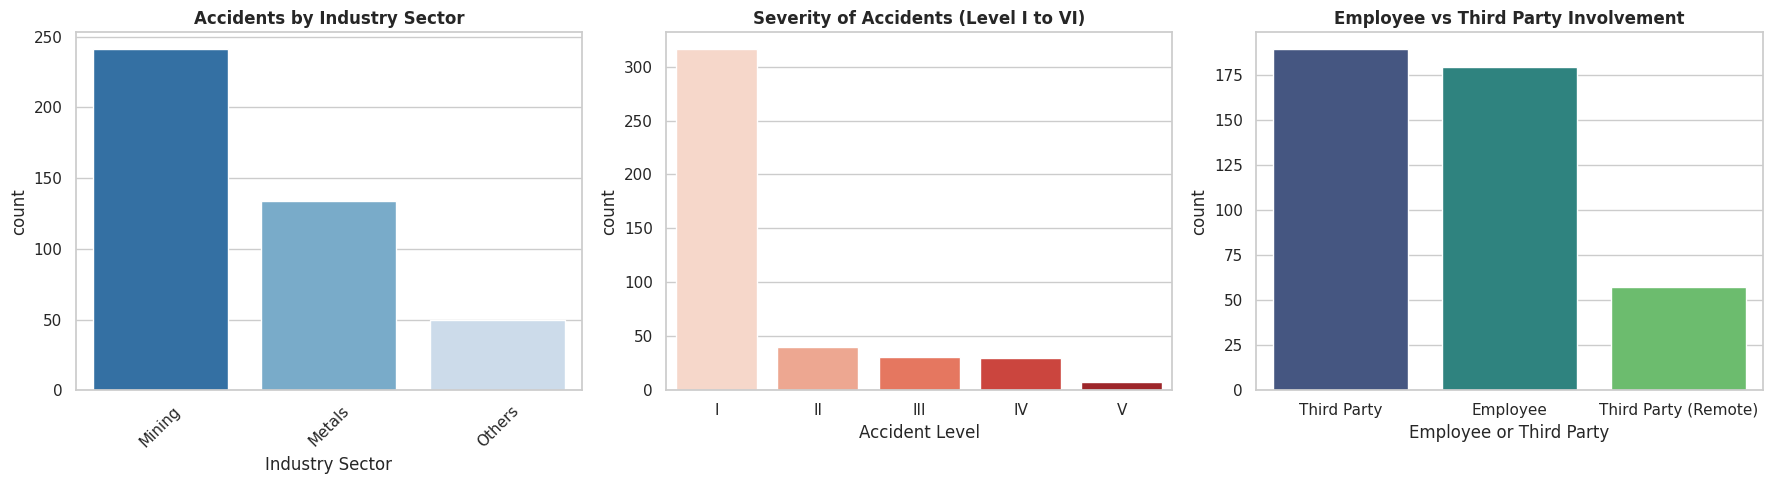


SUCCESS: Initial EDA completed. Data is ready for Feature Engineering.


In [2]:
# ==============================================================================
# WORK HEALTH & SAFETY (WHS) - EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional visualization style for GitHub portfolio
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

print("1. Loading the Industrial Safety Dataset...")
df = pd.read_csv('/content/industrial_safety.csv')

print("\n--- Dataset Overview ---")
print(df.info())

print("\n2. Cleaning Data...")
# Remove the index column if it exported from the database with 'Unnamed: 0'
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Convert the date column to proper datetime format
if 'Data' in df.columns:
    df['Data'] = pd.to_datetime(df['Data'], errors='coerce')

print("\n3. Generating EDA Visualizations...")
# Create a 1x3 dashboard figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Accidents by Industry Sector
sns.countplot(data=df, x='Industry Sector',
              order=df['Industry Sector'].value_counts().index,
              ax=axes[0], palette="Blues_r")
axes[0].set_title('Accidents by Industry Sector', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Accident Levels (Severity)
# Ordering logically from lowest (I) to highest (VI) severity
levels_order = ['I', 'II', 'III', 'IV', 'V', 'VI']
sns.countplot(data=df, x='Accident Level',
              order=[l for l in levels_order if l in df['Accident Level'].unique()],
              ax=axes[1], palette="Reds")
axes[1].set_title('Severity of Accidents (Level I to VI)', fontsize=12, fontweight='bold')

# Plot 3: Internal vs External Workforce
sns.countplot(data=df, x='Employee or Third Party', ax=axes[2], palette="viridis")
axes[2].set_title('Employee vs Third Party Involvement', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nSUCCESS: Initial EDA completed. Data is ready for Feature Engineering.")

1. Feature Engineering: Translating text to machine-readable numbers...
2. Splitting data into Training (80%) and Testing (20%) sets...
3. Training the Random Forest Predictive Model...
4. Model Evaluation on Test Data:
              precision    recall  f1-score   support

           0       0.88      0.74      0.80        68
           1       0.22      0.33      0.27         6
           2       0.10      0.20      0.13         5
           3       0.12      0.25      0.17         4
           4       1.00      0.50      0.67         2

    accuracy                           0.65        85
   macro avg       0.46      0.40      0.41        85
weighted avg       0.75      0.65      0.69        85

5. Generating Feature Importance (What causes the accidents?)...


/tmp/ipykernel_2868/2171758338.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='mako')


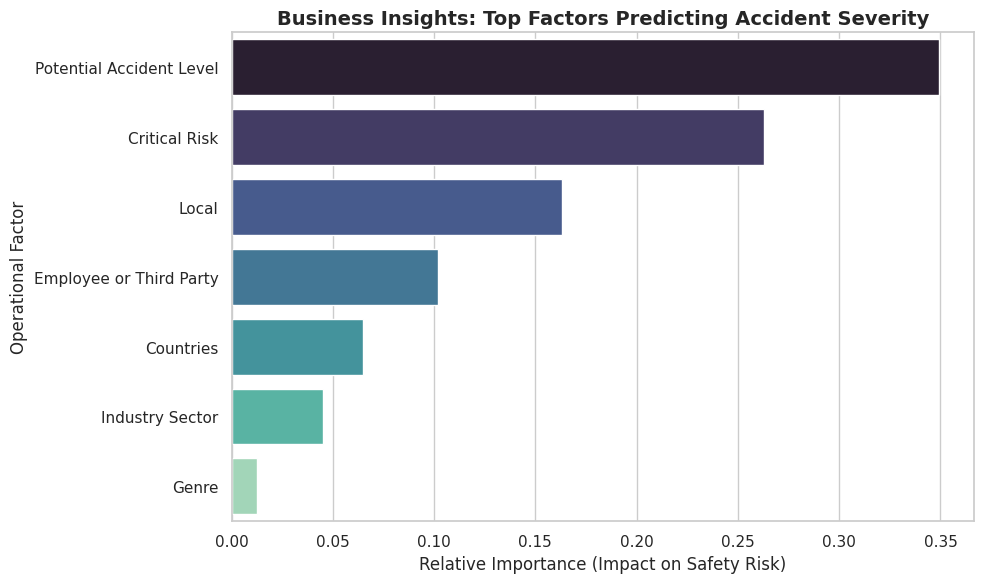


SUCCESS: Machine Learning pipeline executed. Model trained and insights extracted.


In [3]:
# ==============================================================================
# WORK HEALTH & SAFETY - PREDICTIVE MODELING & MACHINE LEARNING
# ==============================================================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("1. Feature Engineering: Translating text to machine-readable numbers...")
# Create a copy of the dataframe to keep the original intact
ml_df = df.copy()

# Drop columns that are free-text or dates (not useful for this basic predictive model)
columns_to_drop = ['Data', 'Description', 'Unnamed: 0']
ml_df = ml_df.drop(columns=[col for col in columns_to_drop if col in ml_df.columns])

# Initialize LabelEncoder
le = LabelEncoder()

# Identify categorical columns and encode them
categorical_cols = ml_df.select_dtypes(include=['object']).columns

# We will save the encoder for the target variable to understand our results later
target_col = 'Accident Level'
feature_cols = [col for col in categorical_cols if col != target_col]

for col in feature_cols:
    ml_df[col] = le.fit_transform(ml_df[col].astype(str))

# Encode the target variable separately
ml_df[target_col] = le.fit_transform(ml_df[target_col].astype(str))

print("2. Splitting data into Training (80%) and Testing (20%) sets...")
X = ml_df.drop(columns=[target_col])
y = ml_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("3. Training the Random Forest Predictive Model...")
# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

print("4. Model Evaluation on Test Data:")
y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

print("5. Generating Feature Importance (What causes the accidents?)...")
# Extract feature importance from the model
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plotting Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='mako')
plt.title('Business Insights: Top Factors Predicting Accident Severity', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance (Impact on Safety Risk)')
plt.ylabel('Operational Factor')
plt.tight_layout()
plt.show()

print("\nSUCCESS: Machine Learning pipeline executed. Model trained and insights extracted.")